# 08 — Results Analysis

One place for the numbers behind the README answers. Everything here is **recomputed from the
cached outputs of notebooks 03–07** (weights, covariance forecasts, VaR forecasts, stress
replays) — no new estimation, no new parameters. The backtests are re-run from the cached
target weights and checked to reproduce `backtest_daily_net.csv` to machine precision.

**Out-of-sample period:** 2010-05-03 → 2026-09-30 (monthly decisions 2010-04-30 → 2026-08-31),
EUR base, 10 bp linear costs, cash/financing at EUR O/N.

## Method map — which technique answers which question

| Question | Technique | Where | Key formula / test |
|---|---|---|---|
| Is the input data right? | Synthetic constant-maturity par bonds, CIP FX hedge, validation gate vs IEF | 01–02 | $R_t = P(y_{t-1}, y_t, M-\Delta t) - 1 + y_{t-1}\Delta t$; $R^h = \frac{1+r_{EUR}\tau}{1+r_f\tau} - 1 + R_f \frac{S_0}{S_1}$ |
| Q1 Which covariance forecasts risk best? | Sample, Rolling, EWMA, Ledoit–Wolf (const. corr.), GARCH(1,1)-CCC | 03 | QLIKE $= \frac{RV}{\hat\sigma^2} - \ln\frac{RV}{\hat\sigma^2} - 1$; Diebold–Mariano (Newey–West) |
| Q2 How do the rules differ? | **Markowitz** min-variance (QP, ADMM), mean–variance ($\gamma=5$), risk parity (CCD), CVaR (Rockafellar–Uryasev LP) | 04 | $\min_w w^\top\Sigma w$; $RC_i = w_i(\Sigma w)_i = \tfrac1N w^\top\Sigma w$; $\min_{w,\zeta}\ \zeta + \tfrac{1}{(1-\beta)S}\sum_s (L_s-\zeta)^+$ |
| Q3 Does the edge survive costs? | Walk-forward backtest with drift, turnover, costs, vol targeting | 05 | $TC = c\sum_i\lvert w_i^{new}-w_i^{pre}\rvert$; Memmel (2003) Sharpe-difference test |
| Q4 What happened in 2022? | Realised OOS windows + buy-and-hold replay with exact attribution | 05, 07 | $\Delta V = \sum_i \text{contribution}_i + \text{cash/financing}$ |
| Q5 Which VaR model passes? | Historical, Normal, EWMA, GARCH-t, **FHS** | 06 | Kupiec LR$_{uc}$, Christoffersen LR$_{ind}$, Basel traffic light, ES ratio |
| Q6 Liabilities? | Surplus optimisation (EIOPA curve) | 09 | $R_S = \tfrac{A}{L}R_A - R_L$ — *pending* |

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import data_loader as dl, risk as K, evaluate as E, backtest as B, var as V

PROC = ROOT / "data" / "processed"
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

# validated categorical palette (fixed order)
C = {"60/40": "#2a78d6", "EW": "#eb6834", "RiskParity*": "#1baf7a", "MinVar": "#eda100",
     "MinVar*": "#e87ba4", "RiskParity": "#008300", "CVaR": "#6250d6", "MV-hist": "#e34948", "CVaR*": "#52514e"}

## 1. Inputs and reproduction check

In [2]:
daily = pd.read_csv(PROC / "asset_returns_eur_daily.csv", index_col="date", parse_dates=True)
weekly = pd.read_csv(PROC / "asset_returns_eur_weekly.csv", index_col="date", parse_dates=True)
NET = pd.read_csv(PROC / "backtest_daily_net.csv", index_col=0, parse_dates=True)
cash = B.daily_cash_returns(daily.index, dl.load_short_rates()["EUR"])
fc = K.load_forecasts(PROC / "cov_forecasts.npz")
ASSETS = fc["assets"]
weekly, daily = weekly[ASSETS], daily[ASSETS]

BASE = ["EW", "60/40", "MinVar", "RiskParity", "CVaR", "MV-hist"]
W = {m: pd.read_csv(PROC / "weights" / f"weights_{m.replace('/', '')}.csv", index_col=0, parse_dates=True)[ASSETS]
     for m in BASE}

runs = {m: B.run_backtest(daily, W[m], cash) for m in BASE}
for m in ["MinVar", "RiskParity", "CVaR"]:          # vol-targeted to the 60/40 ex-ante vol (GARCH-CCC, cap 5)
    lev = B.vol_target_leverage(W[m], fc["cov1w"]["GARCH-CCC"], W["60/40"])
    runs[m + "*"] = B.run_backtest(daily, W[m], cash, leverage=lev)

err = max((runs[m].net - NET[m]).abs().max() for m in NET.columns)
print(f"OOS {NET.index[0].date()} → {NET.index[-1].date()}, {len(fc['dates'])} decisions; "
      f"max |re-run − stored| daily return = {err:.1e}")
assert err < 1e-12

OOS 2010-05-03 → 2026-09-30, 197 decisions; max |re-run − stored| daily return = 1.0e-16


## 2. Scorecard

Sharpe and Sortino use excess returns over EUR O/N cash. The Memmel test compares **monthly**
excess-return Sharpe ratios against 60/40 (two-sided). Stress columns are the buy-and-hold
replay of today's (2026-08-31) targets from notebook 07; *GFC is in-sample for the estimators*.

In [3]:
def monthly_excess(r):
    m = (1 + r).resample("ME").prod() - 1
    c = (1 + cash.reindex(r.index)).resample("ME").prod() - 1
    return m - c

rep = pd.read_csv(PROC / "stress" / "replay_summary.csv", header=[0, 1], index_col=0)["cum_return_pct"]
ORDER = ["60/40", "EW", "MV-hist", "RiskParity*", "RiskParity", "CVaR*", "CVaR", "MinVar*", "MinVar"]
rows = {}
for m in ORDER:
    r = runs[m]
    s = B.perf_stats(r.net, cash, r.turnover, r.cost)
    z, p = (np.nan, np.nan) if m == "60/40" else B.memmel_test(monthly_excess(r.net), monthly_excess(runs["60/40"].net))
    y22 = (1 + r.net.loc["2022"]).prod() - 1
    rows[m] = {"CAGR %": 100 * s["ann. return"], "vol %": 100 * s["ann. vol"], "Sharpe": s["Sharpe"],
               "Sortino": s["Sortino"], "MDD %": 100 * s["max drawdown"], "Calmar": s["Calmar"],
               "turnover p.a.": s["turnover p.a."], "cost bp p.a.": 1e4 * s["cost p.a."],
               "avg lev.": r.leverage.mean() if r.leverage is not None else 1.0,
               "Memmel z": z, "Memmel p": p, "2022 %": 100 * y22,
               "GFC replay %": rep.loc["GFC", m] if m in rep.columns else np.nan,
               "COVID replay %": rep.loc["COVID", m] if m in rep.columns else np.nan,
               "RATES22 replay %": rep.loc["RATES22", m] if m in rep.columns else np.nan}
score = pd.DataFrame(rows).T
score.to_csv(OUT / "scorecard.csv", float_format="%.4f")
score.round(2)

,CAGR %,vol %,Sharpe,Sortino,MDD %,Calmar,turnover p.a.,cost bp p.a.,avg lev.,Memmel z,Memmel p,2022 %,GFC replay %,COVID replay %,RATES22 replay %
60/40,8.370,9.910,0.800,1.120,-20.120,0.420,0.210,2.060,1.000,NaN,NaN,-14.040,-24.370,-19.040,-14.600
EW,4.860,6.000,0.720,1.020,-13.710,0.350,0.230,2.340,1.000,-1.150,0.250,-10.110,-7.320,-11.290,-8.990
MV-hist,8.220,10.370,0.760,1.050,-15.840,0.520,2.780,27.800,1.000,-0.050,0.960,-5.450,NaN,NaN,NaN
RiskParity*,5.730,10.050,0.550,0.760,-32.510,0.180,5.070,50.660,4.170,-2.180,0.030,-30.440,-2.300,-14.260,-30.670
RiskParity,1.740,2.510,0.470,0.660,-8.990,0.190,0.930,9.320,1.000,-2.650,0.010,-8.240,3.180,-3.970,-8.670
CVaR*,2.960,9.440,0.290,0.410,-41.810,0.070,6.010,60.120,3.870,-2.710,0.010,-30.150,NaN,NaN,NaN
CVaR,1.390,2.460,0.330,0.470,-12.480,0.110,0.760,7.570,1.000,-2.630,0.010,-8.530,-1.860,-7.070,-5.850
MinVar*,1.500,9.640,0.140,0.200,-49.000,0.030,8.250,82.450,4.480,-3.700,0.000,-36.600,NaN,NaN,NaN
MinVar,0.800,2.170,0.110,0.150,-11.780,0.070,1.440,14.430,1.000,-3.940,0.000,-9.440,0.240,-5.410,-8.070


### 2.1 Risk–return and wealth

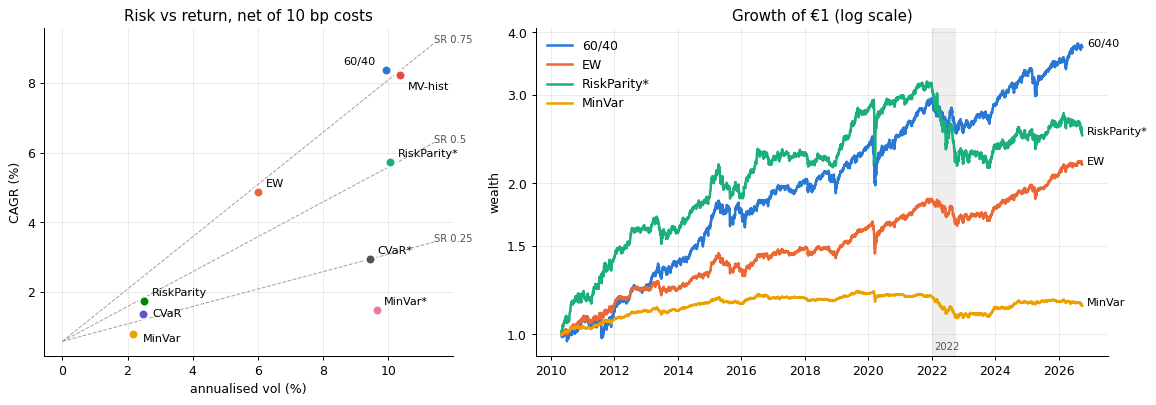

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
for m in ORDER:
    v, c = score.loc[m, "vol %"], score.loc[m, "CAGR %"]
    ax[0].scatter(v, c, s=70, color=C[m], edgecolor="white", linewidth=2, zorder=3)
    off = {"MV-hist": (6, -12), "CVaR": (8, -3), "MinVar": (8, -6), "60/40": (-34, 4)}.get(m, (6, 4))
    ax[0].annotate(m, (v, c), xytext=off, textcoords="offset points", fontsize=9)
cash_cagr = 100 * ((1 + cash.loc[NET.index]).prod() ** (365.25 / (NET.index[-1] - NET.index[0]).days) - 1)
for sr in (0.25, 0.5, 0.75):
    x = np.linspace(0, score["vol %"].max() * 1.1, 10)
    ax[0].plot(x, cash_cagr + sr * x, color="#a3a29c", lw=0.8, ls="--")
    ax[0].annotate(f"SR {sr}", (x[-1], cash_cagr + sr * x[-1]), fontsize=8, color="#52514e")
ax[0].set(xlabel="annualised vol (%)", ylabel="CAGR (%)", title="Risk vs return, net of 10 bp costs")

for m in ["60/40", "EW", "RiskParity*", "MinVar"]:
    w = (1 + runs[m].net).cumprod()
    ax[1].plot(w.index, w, lw=2, color=C[m], label=m)
    ax[1].annotate(m, (w.index[-1], w.iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=9)
ax[1].set_yscale("log")
ax[1].set_yticks([1, 1.5, 2, 3, 4], ["1.0", "1.5", "2.0", "3.0", "4.0"])
ax[1].minorticks_off()
ax[1].axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-10-12"), color="#a3a29c", alpha=0.18, lw=0)
ax[1].annotate("2022", (pd.Timestamp("2022-02-01"), ax[1].get_ylim()[0] * 1.03), fontsize=8, color="#52514e")
ax[1].set(title="Growth of €1 (log scale)", ylabel="wealth")
ax[1].legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "fig1_risk_return_wealth.png", dpi=130, bbox_inches="tight")
plt.show()

## 3. Forecast accuracy vs allocation quality (Q1)

Left: mean QLIKE of next-month variance forecasts for the EW test portfolio (lower = better).
Right: Sharpe of the long-only min-variance portfolio (cap 30%) built from each estimator.
The two rankings are **not** the same — this is the central finding of the project.

In [5]:
fc["next_weeks"] = [w for _, w in K.month_end_schedule(weekly.index, "2010-04-30")]
ports = E.test_portfolios(ASSETS)
tab = E.variance_forecast_table(fc, weekly, ports)
tab["qlike"] = K.qlike(tab["realised"].to_numpy(), tab["forecast"].to_numpy())
q = tab.pivot_table(index="estimator", columns="portfolio", values="qlike", aggfunc="mean")
q["random (mean of 100)"] = q.filter(like="rand").mean(axis=1)
q = q[["EW", "60/40", "random (mean of 100)"]].reindex(K.ESTIMATORS)

est = {}
for e in K.ESTIMATORS:
    w = pd.read_csv(PROC / "weights" / "by_estimator" / f"{e}_MinVar.csv", index_col=0, parse_dates=True)[ASSETS]
    r = B.run_backtest(daily, w, cash)
    s = B.perf_stats(r.net, cash, r.turnover)
    est[e] = {"MinVar Sharpe": s["Sharpe"], "MinVar vol %": 100 * s["ann. vol"], "turnover p.a.": s["turnover p.a."]}
est = pd.DataFrame(est).T
acc = q.join(est)
acc.to_csv(OUT / "estimators.csv", float_format="%.4f")
acc

,EW,60/40,random (mean of 100),MinVar Sharpe,MinVar vol %,turnover p.a.
estimator,,,,,,
Sample,0.637,0.533,0.609,0.203,2.164,0.113
Rolling,0.821,0.587,0.758,0.258,2.229,0.412
EWMA,0.760,0.513,0.697,0.162,2.252,0.776
LedoitWolf,0.819,0.587,0.756,0.210,2.221,0.374
GARCH-CCC,0.561,0.431,0.533,0.109,2.169,1.443


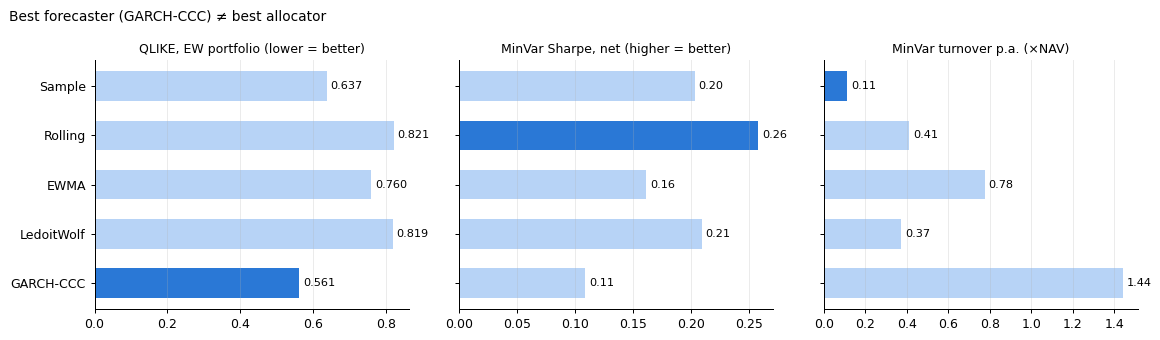

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
names = list(acc.index)
y = np.arange(len(names))
for a, col, title, fmt in [(ax[0], "EW", "QLIKE, EW portfolio (lower = better)", "{:.3f}"),
                           (ax[1], "MinVar Sharpe", "MinVar Sharpe, net (higher = better)", "{:.2f}"),
                           (ax[2], "turnover p.a.", "MinVar turnover p.a. (×NAV)", "{:.2f}")]:
    vals = acc[col].to_numpy()
    best = vals.argmin() if "QLIKE" in title or "turnover" in title else vals.argmax()
    colors = ["#2a78d6" if i == best else "#b7d3f6" for i in range(len(vals))]
    a.barh(y, vals, color=colors, height=0.6)
    for i, v in enumerate(vals):
        a.annotate(fmt.format(v), (v, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=9)
    a.set_title(title, fontsize=10)
    a.grid(axis="y", visible=False)
ax[0].set_yticks(y, names)
ax[0].invert_yaxis()
fig.suptitle("Best forecaster (GARCH-CCC) ≠ best allocator", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "fig2_forecast_vs_allocation.png", dpi=130, bbox_inches="tight")
plt.show()

## 4. Stress: replay of today's portfolios (Q4)

Cumulative buy-and-hold return of the 2026-08-31 targets over each historical window
(notebook 07). Diverging scale: red = loss, blue = gain, grey = 0.

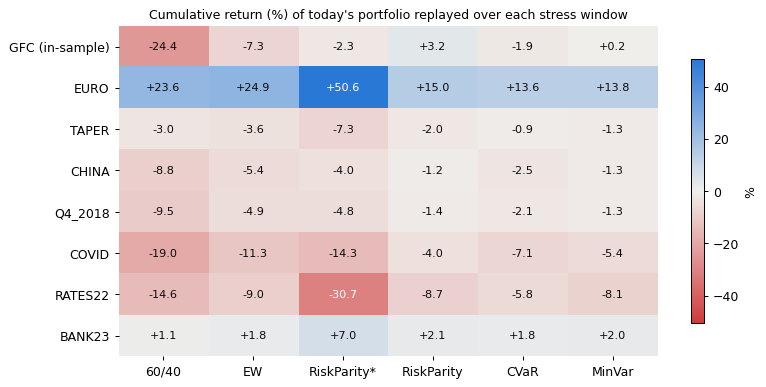

,60/40,EW,RiskParity*,RiskParity,CVaR,MinVar
GFC,-24.400,-7.300,-2.300,3.200,-1.900,0.200
EURO,23.600,24.900,50.600,15.000,13.600,13.800
TAPER,-3.000,-3.600,-7.300,-2.000,-0.900,-1.300
CHINA,-8.800,-5.400,-4.000,-1.200,-2.500,-1.300
Q4_2018,-9.500,-4.900,-4.800,-1.400,-2.100,-1.300
COVID,-19.000,-11.300,-14.300,-4.000,-7.100,-5.400
RATES22,-14.600,-9.000,-30.700,-8.700,-5.800,-8.100
BANK23,1.100,1.800,7.000,2.100,1.800,2.000


In [7]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cols = ["60/40", "EW", "RiskParity*", "RiskParity", "CVaR", "MinVar"]
H = rep[cols]
cmap = LinearSegmentedColormap.from_list("div", ["#d03b3b", "#f0efec", "#2a78d6"])
lim = np.nanmax(np.abs(H.to_numpy()))
fig, ax = plt.subplots(figsize=(9, 4.4))
im = ax.imshow(H.to_numpy(), cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
ax.set_xticks(range(len(cols)), cols)
ax.set_yticks(range(len(H)), [f"{i} (in-sample)" if i == "GFC" else i for i in H.index])
ax.grid(False)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.iat[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.55 * lim else "#0b0b0b")
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Cumulative return (%) of today's portfolio replayed over each stress window", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8, label="%")
fig.tight_layout()
fig.savefig(OUT / "fig3_stress_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()
H.round(1)

In [8]:
# 2022 in one line: rolling 1y SPY–IEF correlation (weekly, EUR) — the hedge that stopped hedging
rho = weekly["SPY"].rolling(52).corr(weekly["IEF"])
print("SPY–IEF 52w corr:  2019-12 {:+.2f} | 2021-12 {:+.2f} | 2022-10 {:+.2f} | 2023-12 {:+.2f} | last {:+.2f}".format(
    *[rho.loc[:d].iloc[-1] for d in ["2019-12-31", "2021-12-31", "2022-10-31", "2023-12-31"]], rho.iloc[-1]))

SPY–IEF 52w corr:  2019-12 -0.38 | 2021-12 -0.34 | 2022-10 +0.05 | 2023-12 -0.06 | last +0.19


## 5. VaR/ES model validation (Q5)

Losses $L_t = -r_t^{net}$ against the 1-day forecasts of notebook 06 (position-based, using the
monthly targets). FHS = filtered historical simulation (GARCH-standardised residuals rescaled
by today's volatility).

In [9]:
FILES = {"60/40": "var_6040.pkl", "EW": "var_EW.pkl", "RiskParity*": "var_RiskParity_vt.pkl"}
vt = []
for p, f in FILES.items():
    fcv = pd.read_pickle(PROC / "var" / f)
    L = -NET[p].reindex(fcv.index)
    t = V.backtest_table(L, fcv)
    t["Basel red %"] = np.nan
    for mdl in fcv.columns.get_level_values(0).unique():
        t.loc[(mdl, "99%"), "Basel red %"] = 100 * V.traffic_light(L, fcv[(mdl, 0.99, "VaR")])["red"]
    t.index = pd.MultiIndex.from_tuples([(p, *i) for i in t.index], names=["portfolio", "model", "level"])
    vt.append(t)
vt = pd.concat(vt)
vt.to_csv(OUT / "var_backtests.csv", float_format="%.4f")
passes = (vt["cond. coverage p"] > 0.05) & (vt["Kupiec p"] > 0.05)
summary = passes.unstack(["portfolio", "level"]).map(lambda b: "pass" if b else "fail")
summary

portfolio  60/40          EW       RiskParity*      
level        95%   99%   95%   99%         95%   99%
model                                               
EWMA        pass  fail  pass  fail        fail  fail
FHS         pass  fail  pass  fail        fail  pass
GARCH-t     pass  fail  pass  fail        fail  fail
Historical  fail  fail  fail  fail        fail  fail
Normal      fail  fail  fail  fail        fail  fail

In [10]:
vt.xs("FHS", level="model")[["exceptions", "expected", "Kupiec p", "Christoffersen p", "loss / ES on exceptions", "Basel red %"]].round(3)

exceptions  expected  ...  loss / ES on exceptions  Basel red %
portfolio   level                        ...                                      
60/40       95%       214.000   213.600  ...                    1.026          NaN
            99%        48.000    42.720  ...                    1.077        0.000
EW          95%       214.000   213.600  ...                    1.026          NaN
            99%        54.000    42.720  ...                    1.030        0.000
RiskParity* 95%       238.000   213.600  ...                    1.025          NaN
            99%        54.000    42.720  ...                    1.038        1.417

[6 rows x 6 columns]

## 6. Answers

**Q1 — Which estimator forecasts risk best?** GARCH(1,1)-CCC has the lowest QLIKE for both test
portfolios and is the only estimator that beats the sample covariance (Diebold–Mariano p ≈ 0.03,
notebook 03). EWMA (half-life 26 w) over-reacts and is worst in COVID; Ledoit–Wolf does not help
forecasting but halves the condition number.

**Q2 — How do the rules differ?** Over 2010–2026 the plain 60/40 wins on Sharpe; EW is
statistically indistinguishable. Every risk-based rule (Markowitz min-variance, risk parity, CVaR)
is **significantly worse** than 60/40 (Memmel p ≤ 0.03, unlevered and vol-targeted) — unlevered they hold too little equity in
an equity bull market; levered to the same ex-ante vol they hold too much duration into 2022.
Historical-mean mean–variance is close to 60/40 only because its equity tilt happened to pay.

**Q3 — Does the edge survive costs?** There is no edge to survive. Costs are second-order for the
monthly rules (≤ ~15 bp p.a. unlevered), but the **estimator choice changes turnover by an order of
magnitude**: GARCH-based min-variance trades ~13× more than sample-based, and its Sharpe is the
lowest even before costs — it chases noise.

**Q4 — 2022.** The 52-week SPY–IEF correlation (EUR, weekly) went from ≈ −0.35 (2019–21) to ≈ 0 by
October 2022 and has not returned to its old level since (−0.06 end-2023, +0.19 now) — the bond
sleeve stopped hedging exactly when yields rose. Calendar-2022 losses:
60/40 −14 %, EW −10 %, vol-targeted risk parity −30 %, vol-targeted min-variance −37 %; MV-hist only −5 % (≈ 30 % gold + 24 % commodities, chosen by trailing means — luck, not foresight). Replaying
today's weights: the same bond-heavy levered risk parity that lost only ~2 % in the GFC loses ~31 %
in the 2022 window. Diversification failure + leverage on the "safe" sleeve is the dominant risk.

**Q5 — VaR.** No model passes everything. Filtered historical simulation (FHS) comes closest:
at 95 % it passes Kupiec, Christoffersen and conditional coverage for 60/40 and EW; at 99 % it gets
the **count** right (Kupiec p = 0.43 for 60/40, 0.10 for EW), has an ES ratio of 1.03–1.08 and never
enters the Basel red zone — but its 99 % exceptions cluster mildly (Christoffersen p = 0.02 / 0.04).
For the levered RP* it is the only model passing at 99 %, but fails independence at 95 %.
Historical simulation gets the 95 % count right yet fails independence everywhere (p < 0.001);
Normal VaR under-counts the 99 % tail by a factor of ≈ 2.

**Q6 — Liabilities.** Pending notebook 09 (ALM v1.5).

## 7. Limitations and next steps

| Limitation | Effect | Next step |
|---|---|---|
| One sample path (2010–2026), GFC in-sample | Conclusions lean on one equity bull market and one bond bear market | Block-bootstrap Sharpe CIs; extend sample with index data |
| Many comparisons (rules × estimators × leverage) | Some p-values will be significant by chance | Holm correction, White Reality Check / Hansen SPA |
| CCC holds correlations constant | Misses the 2022 correlation flip | DCC-GARCH |
| Uniform 10 bp linear cost | Understates synthetic bond / HY trading costs | Asset-specific costs, turnover penalty $\kappa\lVert w-w_{prev}\rVert_1$ |
| Constant-maturity synthetic bonds | Roll-down missing (≈ −0.65 % p.a. vs IEF) | Simulated bond basket |
| Asset-only objective | Ignores what an insurer actually hedges | **09 ALM**: surplus optimisation on EIOPA-discounted liabilities |